# Attendance Trajectories in a parkrun-Style Community Run Series in Russia
## Replicating Grunseit et al. (2024) on S95 data

**Notebook 02 — Building individual attendance trajectories**

---

Mariia Stenina · HSE Faculty of Computer Science · October 2026

## 1. What this notebook does

Grunseit et al. cluster parkrun participants by the *shape* of their attendance
over three years rather than by how much they attend in total. The input to that
clustering is one vector per participant: a 12-week moving sum of runs attended,
measured from each participant's own first run and read off every week from week
12 to week 156.

This notebook turns the S95 export into exactly that matrix and checks it. No
clustering and no modelling here — those are notebooks 03 and 04.

## 2. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path.cwd() / "data"

WINDOW = 156   # weeks of follow-up per participant
MA = 12        # width of the moving-sum window, in weeks

activities = pd.read_csv(DATA / "activities.csv", parse_dates=["date"])
results = pd.read_csv(DATA / "results.csv", dtype={"athlete_id": "Int64"})
events = pd.read_csv(DATA / "events.csv")

print(f"{len(activities):,} runs | {len(results):,} results | {len(events)} locations")

4,378 runs | 146,483 results | 38 locations


## 3. Cohort definition

Two filters apply, and both are design decisions rather than data cleaning, so
they are stated before they are executed.

### 3.1 Geographic restriction

The analysis is restricted to the 31 S95 locations in Russia. Excluded are Brest,
Gomel and Grodno (Belarus), Belgrade and Novi Sad (Serbia), Almaty (Kazakhstan,
no runs held to date), and the aggregate guest record `S95 & Friends` (Belarus).
The aggregate record `С95 и друзья` (Russia) is retained.

The original study compares parkrun locations within one country. Keeping the
comparison country-level means the contrast with Australia is not confounded by
differences in series density, climate and local running culture across four
countries. The cost is small: the eligible cohort loses 2% of its members.

In [2]:
EXCLUDE = {7, 17, 32,   # Brest, Gomel, Grodno — Belarus
           16, 18,      # Belgrade, Novi Sad — Serbia
           38,          # Almaty — Kazakhstan, no runs held
           31}          # "S95 & Friends"

activities_ru = activities[~activities["event_id"].isin(EXCLUDE)]

print(f"locations kept: {activities_ru['event_id'].nunique()}")
print(f"runs kept: {len(activities_ru):,} of {len(activities):,}")

locations kept: 31
runs kept: 3,687 of 4,378


### 3.2 Observation window

A participant enters the cohort only if the data cover a full 156 weeks after
their first run. With the export ending on 26 September 2026, that means a first
run on or before 30 September 2023.

Results with no `athlete_id` are dropped here: an unattributed finish cannot be
placed in anyone's trajectory. They remain valid for location-level statistics
and are not removed from the data as a whole.

In [3]:
runs = (results.dropna(subset=["athlete_id"])
        .merge(activities_ru[["id", "date", "event_id"]],
               left_on="activity_id", right_on="id"))

first_date = runs.groupby("athlete_id")["date"].min()

LAST = runs["date"].max()
cutoff = LAST - pd.Timedelta(weeks=WINDOW)
cohort = first_date[first_date <= cutoff]

print(f"last run in data: {LAST.date()}")
print(f"latest qualifying first run: {cutoff.date()}")
print(f"participants with any linked run: {len(first_date):,}")
print(f"cohort with a full {WINDOW}-week window: {len(cohort):,}"
      f" ({len(cohort) / len(first_date):.1%})")

last run in data: 2026-09-26
latest qualifying first run: 2023-09-30
participants with any linked run: 16,413
cohort with a full 156-week window: 4,278 (26.1%)


In [4]:
cohort

athlete_id
1       2022-03-12
3       2022-09-03
6       2022-08-06
7       2022-06-04
10      2023-07-01
           ...    
31195   2023-07-01
31374   2023-04-15
31447   2022-12-17
31464   2022-11-26
31968   2023-06-03
Name: date, Length: 4278, dtype: datetime64[ns]

In [5]:
runs

,activity_id,athlete_id,total_time,position,first_run,personal_best,id,date,event_id
0,2,3365,980,1,False,True,2,2022-06-18,1
1,2,856,981,2,False,True,2,2022-06-18,1
2,2,908,1045,3,False,True,2,2022-06-18,1
3,2,2625,1056,4,False,False,2,2022-06-18,1
4,2,853,1069,5,False,True,2,2022-06-18,1
...,...,...,...,...,...,...,...,...,...
125237,4887,20504,1410,2,False,False,4887,2026-09-26,27
125238,4887,22822,1975,3,False,False,4887,2026-09-26,27
125239,4887,20039,1978,4,False,False,4887,2026-09-26,27
125240,4887,24540,1978,5,False,False,4887,2026-09-26,27


## 4. Weekly attendance matrix

Week 1 is the week of a participant's own first run, so the clock starts at a
different calendar date for each person. Runs that fall after week 156 belong to
participants who are still active; they are outside the window by construction
and are not counted.

In [6]:
panel = runs[runs["athlete_id"].isin(cohort.index)].copy()
panel["week"] = ((panel["date"] - panel["athlete_id"].map(cohort)).dt.days // 7) + 1

inside = panel["week"].between(1, WINDOW)
print(f"runs inside the window: {inside.sum():,}")
print(f"later runs by cohort members, excluded: {(~inside).sum():,}")

panel = panel[inside]

weekly = (panel.groupby(["athlete_id", "week"]).size()
          .unstack(fill_value=0)
          .reindex(columns=range(1, WINDOW + 1), fill_value=0)
          .reindex(cohort.index, fill_value=0))
weekly.columns.name = "week"

weekly

runs inside the window: 53,933
later runs by cohort members, excluded: 10,846


week,1,2,3,4,5,6,7,8,9,10,...,147,148,149,150,151,152,153,154,155,156
athlete_id,,,,,,,,,,,,,,,,,,,,,
1,1,1,1,1,1,1,1,1,1,1,...,1,0,1,1,1,0,0,1,1,1
3,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,1,0
7,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31195,1,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,1,1,0
31374,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
31447,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


The matrix holds **counts, not flags**. S95 runs happen on Saturday mornings, so
a week almost always holds at most one run — but a participant can appear twice
in one week when a location holds an extra event, and 192 of the 667 368 cells do
(three runs in one week, twice). Keeping counts rather than collapsing to 0/1
matches the original, whose y-axis is "attendances per 12 weeks".

In [7]:
cells = weekly.size
multi = (weekly.to_numpy() > 1).sum()

print(f"matrix: {weekly.shape[0]:,} participants × {weekly.shape[1]} weeks")
print(f"cells holding more than one run: {multi} of {cells:,}"
      f" (max {weekly.to_numpy().max()})")
print(f"total runs in the matrix: {weekly.to_numpy().sum():,}")

matrix: 4,278 participants × 156 weeks
cells holding more than one run: 192 of 667,368 (max 3)
total runs in the matrix: 53,933


## 5. Twelve-week moving sums

Each week from 12 to 156 is replaced by the number of runs attended over that
week and the eleven before it. The first eleven weeks have no complete window
and are dropped, which leaves 145 values per participant.

Smoothing is what makes the shapes clusterable: raw weekly attendance is a sparse
string of zeros and ones, and two people with the same habit would have almost no
weeks in common.

In [8]:
rolling = weekly.T.rolling(MA).sum().T.iloc[:, MA - 1:]

print(f"trajectory matrix: {rolling.shape[0]:,} × {rolling.shape[1]}")
print(f"weeks {rolling.columns[0]} to {rolling.columns[-1]}")

rolling.iloc[:5, :8]

trajectory matrix: 4,278 × 145
weeks 12 to 156


week,12,13,14,15,16,17,18,19
athlete_id,,,,,,,,
1,11.0,11.0,10.0,10.0,10.0,10.0,10.0,10.0
3,3.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0
6,1.0,1.0,2.0,3.0,3.0,3.0,3.0,3.0
7,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 6. Validation

Four checks. The first two would catch an error in aligning weeks to each
participant's own start; the last two are substantive and should match the
pattern the original reports.

In [9]:
# 1. every participant attends in week 1 by definition
assert (weekly[1] >= 1).all(), "someone has no run in their own first week"

# 2. smoothing must not create or lose runs
assert weekly.to_numpy().sum() == len(panel), "run count changed"

# 3. no missing values anywhere
assert rolling.notna().all().all(), "missing values in the trajectory matrix"

print("structural checks passed\n")

for w in (12, 52, 104, 156):
    col = rolling[w]
    print(f"week {w:3}:  mean {col.mean():.2f}   median {col.median():.0f}"
          f"   zero attendance {(col == 0).mean():6.1%}")

structural checks passed

week  12:  mean 2.46   median 1   zero attendance   0.0%
week  52:  mean 0.95   median 0   zero attendance  70.5%
week 104:  mean 0.82   median 0   zero attendance  76.0%
week 156:  mean 0.76   median 0   zero attendance  78.9%


Average attendance over a 12-week window falls from 2.46 runs at week 12 to 0.76
at week 156, and the share of the cohort with no attendance at all in the current
window rises to 78.9%. That is heavy attrition — and the same picture the original
reports for Australia, where the largest cluster is also people who try the event
and leave.

The median sits at zero from week 52 onward. This is why the study clusters on
trajectory shape instead of summarising attendance with an average: for most of
the follow-up the typical participant is simply absent, and a mean of 0.76 runs
describes the mixture rather than any individual in it.

## 7. The average trajectory

Two separate charts rather than one with two axes: the quantities differ in both
units and meaning.

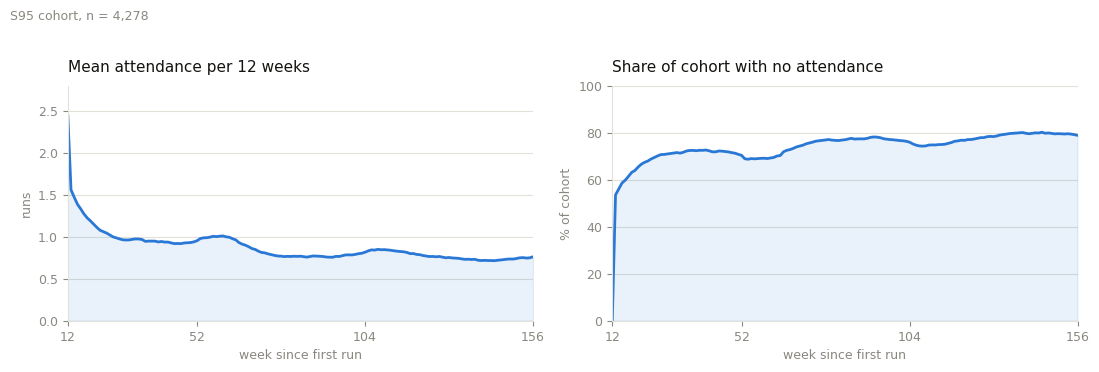

In [10]:
INK, MUTED, GRID, ACCENT = "#14130f", "#8a8780", "#e1e0d9", "#2a78d6"
weeks = rolling.columns.to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

for ax, y, title, ylab, ymax in [
    (axes[0], rolling.mean().to_numpy(),
     "Mean attendance per 12 weeks", "runs", 2.8),
    (axes[1], (rolling == 0).mean().to_numpy() * 100,
     "Share of cohort with no attendance", "% of cohort", 100),
]:
    ax.plot(weeks, y, color=ACCENT, linewidth=2, solid_capstyle="round")
    ax.fill_between(weeks, y, color=ACCENT, alpha=0.10)
    ax.set_title(title, fontsize=11, color=INK, loc="left", pad=10)
    ax.set_xlabel("week since first run", fontsize=9, color=MUTED)
    ax.set_ylabel(ylab, fontsize=9, color=MUTED)
    ax.set_xlim(12, 156)
    ax.set_ylim(0, ymax)
    ax.set_xticks([12, 52, 104, 156])
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=9)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)

fig.suptitle(f"S95 cohort, n = {len(rolling):,}", fontsize=9,
             color=MUTED, x=0.005, ha="left", y=1.02)
fig.tight_layout()
plt.show()

## 8. Output

Both matrices are written to `data/derived/`, which sits inside the git-ignored
`data/` folder — the S95 export is not ours to redistribute, and neither is
anything derived from it at participant level.

In [11]:
OUT = DATA / "derived"
OUT.mkdir(exist_ok=True)

weekly.to_csv(OUT / "weekly_attendance.csv.gz", compression="gzip")
rolling.to_csv(OUT / "trajectories_12w.csv.gz", compression="gzip")

cohort.rename("first_date").to_frame().assign(
    first_location=panel.groupby("athlete_id")["event_id"].first(),
    runs_in_window=weekly.sum(axis=1),
).to_csv(OUT / "cohort.csv")

for f in sorted(OUT.iterdir()):
    print(f"{f.name:28} {f.stat().st_size / 1024:7.0f} KB")

cohort.csv                        86 KB
trajectories_12w.csv.gz           78 KB
weekly_attendance.csv.gz          51 KB


In [13]:
n_runs = weekly.sum(axis=1)          # забегов за три года

shares = pd.Series({
    "ровно 1 забег":  (n_runs == 1).mean(),
    "2–4 забега":     n_runs.between(2, 4).mean(),
    "5–11":           n_runs.between(5, 11).mean(),
    "12 и больше":    (n_runs >= 12).mean(),
}).round(3)

# на какой неделе случился второй забег
second = weekly.apply(
    lambda r: r[r > 0].index[1] if (r > 0).sum() > 1 else pd.NA, axis=1
).dropna()

print(shares)
print(second.describe())
print("вернулись в первые 2 недели:", round((second <= 2).mean(), 3))
print("в первый месяц:",              round((second <= 4).mean(), 3))

ровно 1 забег    0.346
2–4 забега       0.221
5–11             0.152
12 и больше      0.281
dtype: float64
count     2799
unique     138
top          2
freq       813
dtype: int64
вернулись в первые 2 недели: 0.29
в первый месяц: 0.502


In [14]:
first_loc = runs.sort_values("date").groupby("athlete_id")["event_id"].first()

ret = (pd.DataFrame({"loc": first_loc.reindex(n_runs.index), "runs": n_runs})
       .groupby("loc")
       .agg(новичков=("runs", "size"),
            вернулись=("runs", lambda s: (s >= 2).mean()),
            медиана=("runs", "median"))
       .join(events.set_index("id")["name"])
       .sort_values("вернулись"))

ret[ret["новичков"] >= 50]

,новичков,вернулись,медиана,name
loc,,,,
4,313,0.246006,1.0,С95 и друзья
5,401,0.653367,3.0,Царицыно
1,1418,0.653738,3.0,Кузьминки
14,119,0.680672,4.0,Саранск
3,498,0.708835,5.0,Измайлово
11,252,0.710317,3.0,Троицк
2,103,0.718447,3.0,Олимпийская Деревня
9,281,0.722420,4.0,Тверь
13,221,0.723982,7.0,Великий Новгород


## 9. Summary and next steps

The cohort is 4 278 participants who first ran at one of 31 Russian S95 locations
on or before 30 September 2023, each observed for 156 weeks from their own first
run. The trajectory matrix is 4 278 × 145 and complete, with no imputation.

Three questions carry into notebook 03.

**Whether to cluster the whole cohort.** The median participant runs three times
in three years, and 56% run fewer than five times. Grunseit et al. keep every
first-timer, and one of their clusters is correspondingly large and flat; the
alternative is a minimum-runs threshold, which changes what the clusters mean.

**Which implementation.** The original uses the R package `kml`, which handles
missing values in longitudinal k-means. This matrix has none by construction, so
k-means on the 145-dimensional vectors is equivalent in substance — but that is a
departure from the original and should be stated, and ideally checked once in R.

**How many clusters.** Selected with the indices the original uses:
Calinski–Harabasz, Davies–Bouldin and Ray–Turi.